The following notebook contains some basic data exploration into the `.json` files in `data/raw/h1n1pdm` and `data/raw/h3n2`.

In [8]:
import json

file_paths = {
    "h1n1pdm": {
        "root": "raw/h1n1pdm/seasonal-flu_h1n1pdm_ha_12y_root-sequence.json",
        "tip": "raw/h1n1pdm/seasonal-flu_h1n1pdm_ha_12y_tip-frequencies.json",
        "metadata": "raw/h1n1pdm/seasonal-flu_h1n1pdm_ha_12y.json"
    },
    "h3n2": {
        "root": "raw/h3n2/seasonal-flu_h3n2_ha_12y_root-sequence.json",
        "tip": "raw/h3n2/seasonal-flu_h3n2_ha_12y_tip-frequencies.json",
        "metadata": "raw/h3n2/seasonal-flu_h3n2_ha_12y.json"
    }
}

data = {}

for subtype, files in file_paths.items():
    data[subtype] = {}

    for file_type, path in files.items():
        with open(path, "r") as f:
            data[subtype][file_type] = json.load(f)

h1n1_root = data["h1n1pdm"]["root"]
h1n1_tip = data["h1n1pdm"]["tip"]
h1n1_metadata = data["h1n1pdm"]["metadata"]

h3n2_root = data["h3n2"]["root"]
h3n2_tip = data["h3n2"]["tip"]
h3n2_metadata = data["h3n2"]["metadata"]

The root sequence datasets, stored as `h1n1_root` and `h3n2_root` contain sequence data for the pathogen at the root of the tree:

In [63]:
print(h1n1_root.keys())
print(h3n2_root.keys())

dict_keys(['HA1', 'HA2', 'SigPep', 'nuc'])
dict_keys(['HA1', 'HA2', 'SigPep', 'nuc'])


`HA1`, `HA2`, and `SigPep` contain amino-acid sequences corresponding to different regions of the haemagglutinin (HA) protein, while `nuc` contains the nucleotide sequence of the HA gene

In [68]:
print(f'h1n1 HA1: {h1n1_root["HA1"][:50]}...')
print(f'h1n1 HA2: {h1n1_root["HA2"][:50]}...')
print(f'h1n1 SigPep: {h1n1_root["SigPep"]}')
print(f'h1n1 nuc: {h1n1_root["nuc"][:50]}...')

h1n1 HA1: DTLCIGYHANNSTDTVDTVLEKNVTVTHSVNLLEDKHNGKLCKLRGVAPL...
h1n1 HA2: GLFGAIAGFIEGGWTGMVDGWYGYHHQNEQGSGYAADLKSTQNAIDEITN...
h1n1 SigPep: MKAILVVLLYTFATANA
h1n1 nuc: GGAAAACAAAAGCAACAAAAATGAAGGCAATACTAGTAGTTCTGCTATAT...


The tip sequence datasets, stored as `h1n1_tip` and `h3n2_tip` contain estimated relative frequences of individual sampled tips over time. This can be thought of as a matrix $F \in \mathbb R^{n\times T}$ where $n$ is the number tips in the sample and $T$ is the number of time periods. The time periods are specified in the `pivots` key of the dictionary. Below is a plot of the estimated frequency trajectories of four samples taken in Ontario, Canada.

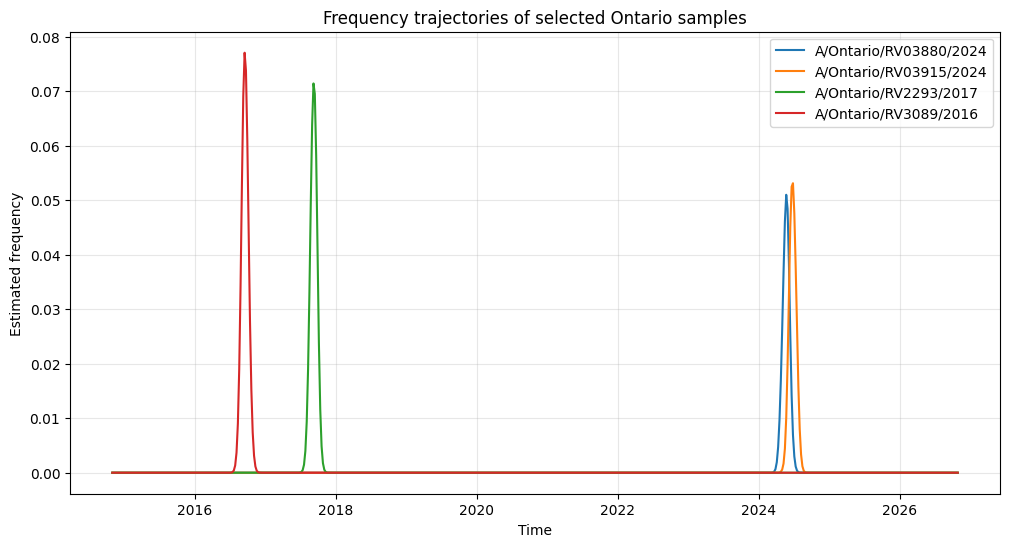

In [98]:
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt

ontario_sample = [
    'A/Ontario/RV03880/2024',
    'A/Ontario/RV03915/2024',
    'A/Ontario/RV2293/2017',
    'A/Ontario/RV3089/2016'
]

pivots = h1n1_tip["pivots"]

plt.figure(figsize=(12, 6))

for sample in ontario_sample:
    frequencies = h1n1_tip[sample]["frequencies"]
    plt.plot(pivots, frequencies, label=sample)

plt.xlabel("Time")
plt.ylabel("Estimated frequency")
plt.title("Frequency trajectories of selected Ontario samples")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The metadata, stored as `h1n1_metadata` and `h3n2_metadata` contain the following keys:
- `version`: Auspice JSON schema version.
- `meta`: Schema, visualization settings, and annotations.
- `tree`: The actual phylogenetic tree containing nodes, attributes, and branch mutations.
- `root_sequence`: Inferred ancestral sequences.

The `meta` dictionary contains some description of the attributes that will be used in our construction of the mutation graph.

In [99]:
h1n1_metadata['meta']['colorings']

[{'key': 'gt', 'title': 'Genotype', 'type': 'categorical'},
 {'key': 'num_date', 'title': 'Date', 'type': 'continuous'},
 {'key': 'clade_membership', 'title': 'Clade', 'type': 'categorical'},
 {'key': 'subclade',
  'title': 'Subclade',
  'type': 'categorical',
  'scale': [['C.1.9', '#4272CE'],
   ['C.1.9.1', '#58A2AC'],
   ['C.1.9.3', '#7DB877'],
   ['D.1', '#AEBD50'],
   ['D.3.1', '#D8AE3E'],
   ['D.3.1.1', '#E67A32'],
   ['D.5', '#DB2823']]},
 {'key': 'subclade_nextclade_ha',
  'title': 'HA subclade (Nextclade)',
  'type': 'categorical'},
 {'key': 'subclade_nextclade_na',
  'title': 'NA subclade (Nextclade)',
  'type': 'categorical'},
 {'key': 'emerging_haplotype_ha',
  'title': 'Emerging haplotype',
  'type': 'categorical',
  'scale': [['C.1.9.3', '#5098B9'],
   ['D.3.1', '#6CB28C'],
   ['D.3.1.1', '#BFBB47'],
   ['D.3.1.1:139N', '#DFA53B'],
   ['D.3.1.1:155E', '#E67131'],
   ['D.3.1.1:205K', '#DB2823']]},
 {'key': 'haplotype', 'title': 'Derived haplotype', 'type': 'categorical'},
 

The actual data is stored in the `tree` dictionary. Each node in the tree comes with the following subdictionaries:
- `name`: the name of the node.
- `node_attrs`: a dictionary of node attributes (described in `meta`).
- `branch_attrs`: a dictionary of edge attributes (described in `meta`).
- `childern`: a list of the current node's child nodes.

For example, we can find the first child node's node attributes:

In [123]:
print(f'First child of root node: {h1n1_metadata["tree"]["children"][1]["name"]}\n')
print(f"{h1n1_metadata['tree']['children'][1]['name']}'s node attributes:")
h1n1_metadata["tree"]["children"][1]['node_attrs']

First child of root node: NODE_0000001

NODE_0000001's node attributes:


{'div': 0.00507386,
 'num_date': {'value': 2010.308, 'confidence': [2009.885, 2010.884]},
 'lbi': {'value': 0.124},
 'ha_muts': {'value': 6},
 'ep': {'value': 2.0},
 'glyc': {'value': 0},
 'region': {'value': 'North America',
  'confidence': {'North America': 0.241,
   'Oceania': 0.14,
   'South Asia': 0.136,
   'Europe': 0.107,
   'Africa': 0.0811,
   'West Asia': 0.0758,
   'Southeast Asia': 0.0639,
   'China': 0.0589,
   'Japan Korea': 0.0498,
   'South America': 0.0462},
  'entropy': 2.162},
 'cTiterSub': {'value': 1.53e-06},
 'lcr_sum': {'value': 0.0},
 'ha1_muts': {'value': 4},
 'subclade': {'value': 'unassigned'},
 'clade_membership': {'value': 'unassigned'},
 'haplotype': {'value': 'unassigned'},
 'cTiter': {'value': 0}}